# Multimodal survival results: GBM and LGG
Compare **late fusion** and **cross-attention** within each cohort using saved summaries, prediction CSVs, and matching histories. No training is performed. Missing experiments are reported rather than substituted with another cohort's data.

For NLL survival models, C-index evaluates ranking using censored outcomes. Event-bin accuracy and confusion matrices use observed deaths only. Historical classification objectives are labeled separately. Model runs may differ in objectives, patient splits, interval boundaries, and architecture revisions; compare them as saved experiments, not as a controlled architecture-only benchmark.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "main.py").is_file() and (p / "result").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from utils.metrics_utils import concordance_index

COHORTS = {"GBM": ["normalized_zscore_gbm.csv", "gbm", "gbm.csv"],
           "LGG": ["normalized_zscore_lgg.csv", "lgg", "lgg.csv"]}
MODELS = {"Late fusion": "multimodal_late_fusion", "Cross-attention": "multimodal_cross_attention"}
FOLD = 0  # One validation fold for confusion matrices and epoch histories.
OUTPUT_DIR = ROOT / "result/comparisons/multimodal"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SAVED_FIGURES = []

def save_figure(fig, name):
    for extension in ["png", "pdf"]:
        path = OUTPUT_DIR / f"{name}.{extension}"
        fig.savefig(path, dpi=300, bbox_inches="tight")
    SAVED_FIGURES.append(OUTPUT_DIR / f"{name}.png")
    print("Saved:", SAVED_FIGURES[-1])
    plt.show()
    plt.close(fig)

def normalize_loss_name(value):
    value = str(value).strip().lower()
    if value in {"cross_entropy", "ce", "cross-entropy", "crossentropyloss"}:
        return "Cross entropy"
    if value in {"nll_surv", "nll_survival", "nll_loss", "nllsurvloss", "nllsurvloss()", "lossclass", "lossclass()"}:
        return "NLLSurvLoss"
    if value in {"sigmoid", "bce", "bcewithlogits", "bcewithlogitsloss"}:
        return "BCEWithLogitsLoss"
    return "Unknown"

def identify_loss(frame, model, dataset):
    # Prefer explicit run metadata; file headers are a fallback for older results.
    for column in ["loss_func", "loss_function"]:
        if column in frame and frame[column].notna().any():
            names = {normalize_loss_name(value) for value in frame[column].dropna()}
            return (names.pop() if len(names) == 1 else "Mixed"), f"Summary column: {column}"
    flags = []
    for fold in frame["fold"]:
        path = ROOT / "result" / f"split_{model}_{dataset}_{int(fold)}_predictions.csv"
        if path.exists():
            flags.append("survival_tail_probability" in pd.read_csv(path, nrows=0).columns)
    if flags and all(flags):
        return "NLLSurvLoss", "Inferred from survival prediction columns; summary has no loss metadata"
    # Absence of hazards cannot distinguish cross-entropy from sigmoid BCE.
    return "Unverified", "Loss metadata unavailable; classification predictions do not identify CE vs BCE"

runs, availability, tables = {}, [], []
for cohort, dataset_names in COHORTS.items():
    for name, model in MODELS.items():
        summary_path = next((ROOT / "result" / model / dataset / "summary.csv"
                             for dataset in dataset_names
                             if (ROOT / "result" / model / dataset / "summary.csv").exists()), None)
        availability.append({"Cohort": cohort, "Model": name, "Status": "Available" if summary_path else "No saved summary"})
        if summary_path is None:
            print(f"{cohort} {name}: no results at result/{model}/{dataset_names[0]}/summary.csv")
            continue
        frame = pd.read_csv(summary_path)
        frame = frame[pd.to_numeric(frame["fold"], errors="coerce").notna()].copy()
        frame["fold"] = frame["fold"].astype(int)
        frame["Cohort"], frame["Model"] = cohort, name
        frame["Dataset"] = summary_path.parent.name
        loss_name, loss_source = identify_loss(frame, model, summary_path.parent.name)
        frame["Loss function"], frame["Loss source"] = loss_name, loss_source
        runs[(cohort, name)] = {"model": model, "dataset": summary_path.parent.name, "summary": frame, "path": summary_path}
        tables.append(frame)
availability = pd.DataFrame(availability)
display(availability)
availability.to_csv(OUTPUT_DIR / "gbm_lgg_result_availability.csv", index=False)
fold_results = pd.concat(tables, ignore_index=True) if tables else pd.DataFrame()


,Cohort,Model,Status
0,GBM,Late fusion,Available
1,GBM,Cross-attention,Available
2,LGG,Late fusion,Available
3,LGG,Cross-attention,Available


## Mean training and validation results
Means and standard deviations are calculated from numeric fold rows, excluding precomputed average rows.

,Cohort,Model,Status,Folds,Loss function,Loss source,train_cindex_mean,train_cindex_std,final_val_cindex_mean,final_val_cindex_std,train_loss_mean,train_loss_std,final_val_loss_mean,final_val_loss_std,C-index gap (train - validation)
0,GBM,Late fusion,Available,5,NLLSurvLoss,Inferred from survival prediction columns; sum...,0.8964,0.0067,0.5757,0.0331,0.2170,0.0184,1.9654,0.1657,0.3207
1,GBM,Cross-attention,Available,5,NLLSurvLoss,Inferred from survival prediction columns; sum...,0.8965,0.0108,0.5886,0.0366,0.1507,0.0060,2.5410,0.2196,0.3080
2,LGG,Late fusion,Available,5,NLLSurvLoss,Inferred from survival prediction columns; sum...,0.9627,0.0042,0.7968,0.0163,0.0669,0.0138,0.8018,0.1621,0.1659
3,LGG,Cross-attention,Available,5,NLLSurvLoss,Inferred from survival prediction columns; sum...,0.9630,0.0074,0.8009,0.0150,0.0464,0.0123,1.0142,0.1579,0.1620


,Cohort,Model,Loss function,fold,train_cindex,final_val_cindex,train_loss,final_val_loss
0,GBM,Late fusion,NLLSurvLoss,0,0.899545,0.560816,0.237388,1.897858
1,GBM,Late fusion,NLLSurvLoss,1,0.900376,0.528340,0.219548,2.209302
2,GBM,Late fusion,NLLSurvLoss,2,0.900894,0.604911,0.189032,1.814665
3,GBM,Late fusion,NLLSurvLoss,3,0.884893,0.608519,0.227677,1.845952
4,GBM,Late fusion,NLLSurvLoss,4,0.896318,0.576023,0.211108,2.059354
5,GBM,Cross-attention,NLLSurvLoss,0,0.903022,0.557551,0.154437,2.439641
6,GBM,Cross-attention,NLLSurvLoss,1,0.882817,0.546559,0.151240,2.845512
7,GBM,Cross-attention,NLLSurvLoss,2,0.888045,0.614955,0.154916,2.346943
8,GBM,Cross-attention,NLLSurvLoss,3,0.900137,0.591278,0.152406,2.697884
9,GBM,Cross-attention,NLLSurvLoss,4,0.908692,0.632554,0.140309,2.374969


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/multimodal/gbm_fusion_training_validation.png


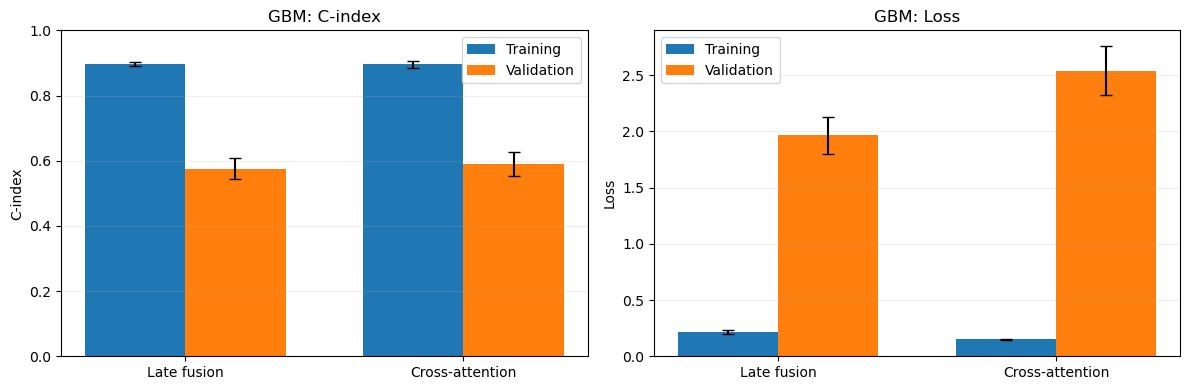

Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/multimodal/lgg_fusion_training_validation.png


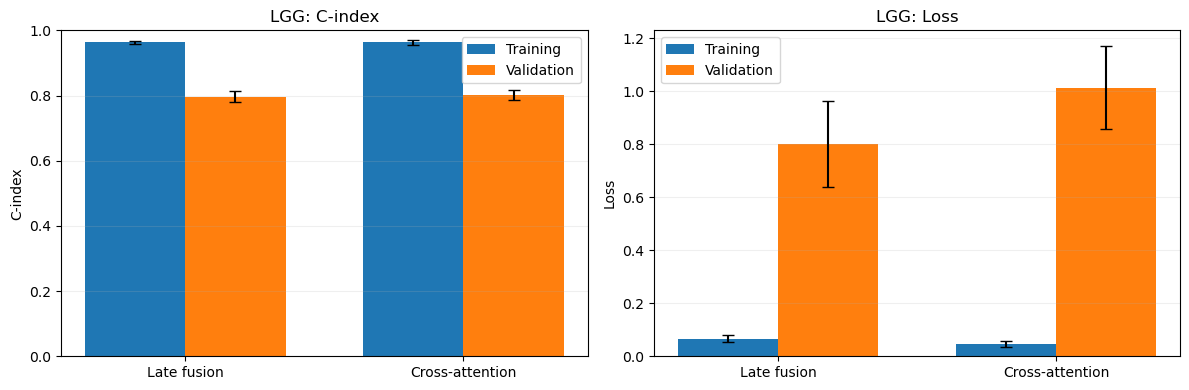

Loss magnitudes are comparable only for matching objectives and interval definitions.


In [2]:
metric_columns = ["train_cindex", "final_val_cindex", "train_loss", "final_val_loss"]
mean_rows = []
for (cohort, name), run in runs.items():
    frame = run["summary"]
    row = {"Cohort": cohort, "Model": name, "Folds": len(frame),
           "Loss function": frame["Loss function"].iloc[0], "Loss source": frame["Loss source"].iloc[0]}
    for metric in metric_columns:
        row[f"{metric}_mean"] = frame[metric].mean()
        row[f"{metric}_std"] = frame[metric].std()
    row["C-index gap (train - validation)"] = (frame["train_cindex"] - frame["final_val_cindex"]).mean()
    mean_rows.append(row)
mean_results = pd.DataFrame(mean_rows)
comparison = availability.merge(mean_results, on=["Cohort", "Model"], how="left") if mean_rows else availability.copy()
display(comparison.round(4))
comparison.to_csv(OUTPUT_DIR / "gbm_lgg_fusion_mean_results.csv", index=False)
if not fold_results.empty:
    display(fold_results[["Cohort", "Model", "Loss function", "fold"] + metric_columns])
    fold_results.to_csv(OUTPUT_DIR / "gbm_lgg_fusion_fold_results.csv", index=False)

for cohort in COHORTS:
    available = [(name, runs[(cohort, name)]["summary"]) for name in MODELS if (cohort, name) in runs]
    if not available:
        print(f"{cohort}: training/validation plots will be available after training.")
        continue
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    xpos = np.arange(len(available))
    for ax, train_col, val_col, title in [
        (axes[0], "train_cindex", "final_val_cindex", "C-index"),
        (axes[1], "train_loss", "final_val_loss", "Loss"),
    ]:
        for offset, column, label in [(-0.18, train_col, "Training"), (0.18, val_col, "Validation")]:
            means = [frame[column].mean() for _, frame in available]
            stds = [frame[column].std() if len(frame) > 1 else 0 for _, frame in available]
            ax.bar(xpos + offset, means, yerr=stds, width=0.36, capsize=4, label=label)
        ax.set(xticks=xpos, xticklabels=[name for name, _ in available], ylabel=title, title=f"{cohort}: {title}")
        ax.legend()
        ax.grid(axis="y", alpha=0.2)
    axes[0].set_ylim(0, 1)
    fig.tight_layout()
    save_figure(fig, f"{cohort.lower()}_fusion_training_validation")
print("Loss magnitudes are comparable only for matching objectives and interval definitions.")


## All models: mean training and validation results
Mean ± standard deviation across every available fold for each saved model and dataset. Includes genomic, WSI, MRI, and fusion models. Dataset variants remain separate. Validation is the held-out fold; these are not independent external-test results. Single-fold results show a mean without a standard deviation; unavailable metrics are marked explicitly. Numeric exports include the valid fold count for each metric.

**Average C-index** = (mean training C-index + mean validation C-index) / 2 per model/run. This is a descriptive average, not an independent test score.

In [ ]:
# Keep each saved dataset variant separate; do not combine overlapping runs.
MODEL_NAMES = {
    "snn": "SNN", "mlp": "MLP", "gen2vec": "Gene2Vec", "resmlp": "ResMLP",
    "mil": "WSI MIL", "transmil": "WSI TransMIL", "ViT": "MRI ViT",
    "3dcnn": "MRI 3D CNN", "multimodal_late_fusion": "WSI + gene: late fusion",
    "multimodal_cross_attention": "WSI + gene: cross-attention",
    "multimodal_mri_late_fusion": "MRI + gene: late fusion",
    "multimodal_mri_cross_attention": "MRI + gene: cross-attention",
}
METRICS = {
    "train_cindex": "Training C-index", "final_val_cindex": "Validation C-index",
    "train_loss": "Training loss", "final_val_loss": "Validation loss",
    "train_acc": "Training accuracy", "final_val_acc": "Validation accuracy",
}
all_model_rows = []
for summary_path in sorted((ROOT / "result").glob("*/*/summary.csv")):
    frame = pd.read_csv(summary_path)
    if "fold" not in frame.columns:
        print("Skipping summary with missing metrics:", summary_path.relative_to(ROOT))
        continue
    # Exclude saved 'average' rows so every actual fold contributes exactly once.
    fold_numbers = pd.to_numeric(frame["fold"], errors="coerce")
    frame = frame.loc[fold_numbers.notna() & (fold_numbers >= 0)
                      & (fold_numbers % 1 == 0)].copy()
    if frame.empty:
        continue
    frame["fold"] = pd.to_numeric(frame["fold"]).astype(int)
    if frame["fold"].duplicated().any():
        raise ValueError(f"Duplicate fold rows in {summary_path}")
    model, dataset = summary_path.parent.parent.name, summary_path.parent.name
    dataset_lower = dataset.lower()
    cohort = ("GBM + LGG" if "gbm" in dataset_lower and "lgg" in dataset_lower
              else "GBM" if "gbm" in dataset_lower
              else "LGG" if "lgg" in dataset_lower else "Unspecified")
    loss_name, loss_source = identify_loss(frame, model, dataset)
    row = {"Cohort": cohort, "Model": MODEL_NAMES.get(model, model),
           "Dataset": dataset, "Folds": len(frame), "Loss function": loss_name,
           "Loss source": loss_source, "Summary": str(summary_path.relative_to(ROOT))}
    for metric, label in METRICS.items():
        values = pd.to_numeric(frame.get(metric, pd.Series(np.nan, index=frame.index)), errors="coerce").replace([np.inf, -np.inf], np.nan)
        row[f"{label} mean"] = values.mean()
        row[f"{label} std"] = values.std()
        row[f"{label} valid folds"] = values.count()
    all_model_rows.append(row)

all_model_mean_results = pd.DataFrame(all_model_rows)
if all_model_mean_results.empty:
    print("No model summaries with training and validation metrics were found.")
else:
    all_model_mean_results = all_model_mean_results.sort_values(
        ["Cohort", "Model", "Dataset"]
    ).reset_index(drop=True)
    all_model_mean_results["Average C-index"] = (all_model_mean_results["Training C-index mean"] + all_model_mean_results["Validation C-index mean"]) / 2
    model_comparison_table = all_model_mean_results[
        ["Cohort", "Model", "Dataset", "Folds", "Loss function"]
    ].copy()
    for label in METRICS.values():
        model_comparison_table[label] = [
            "Unavailable" if pd.isna(mean) else f"{mean:.3f}" if pd.isna(std)
            else f"{mean:.3f} ± {std:.3f}"
            for mean, std in zip(all_model_mean_results[f"{label} mean"],
                                 all_model_mean_results[f"{label} std"])
        ]
    model_comparison_table["Average C-index"] = all_model_mean_results["Average C-index"].round(3)
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(model_comparison_table)
    all_model_mean_results.to_csv(OUTPUT_DIR / "all_models_mean_results.csv", index=False)
    model_comparison_table.to_csv(OUTPUT_DIR / "all_models_comparison_table.csv", index=False)
    print(f"Included {len(model_comparison_table)} saved model/dataset runs. Values: mean ± fold standard deviation.")
    print("Loss comparisons require the same objective; patient sets and saved run settings may differ.")


Cohort,Model,Dataset,Folds,Loss function,Training C-index,Validation C-index,Training loss,Validation loss,Training accuracy,Validation accuracy,Average C-index
GBM,Gene2Vec,normalized_zscore_gbm.csv,5,NLLSurvLoss,0.631 ± 0.136,0.556 ± 0.060,1.383 ± 0.619,1.654 ± 0.160,Unavailable,Unavailable,0.593
GBM,MLP,gbm.csv,5,Unverified,0.743 ± 0.019,0.556 ± 0.043,0.703 ± 0.051,1.646 ± 0.345,Unavailable,Unavailable,0.649
GBM,MLP,gbm_filtered.csv,5,Unverified,Unavailable,Unavailable,1.300 ± 0.005,1.406 ± 0.038,0.398 ± 0.033,0.284 ± 0.071,NaN
GBM,MLP,normalized_minmax_gbm.csv,5,Unverified,Unavailable,Unavailable,1.391 ± 0.010,1.388 ± 0.015,0.256 ± 0.027,0.295 ± 0.045,NaN
GBM,MLP,normalized_minmax_gbm_reduce_column.csv,5,Unverified,Unavailable,Unavailable,1.392 ± 0.009,1.388 ± 0.013,0.250 ± 0.025,0.267 ± 0.082,NaN
GBM,MLP,normalized_zscore_gbm.csv,5,NLLSurvLoss,0.506 ± 0.028,0.509 ± 0.042,1.678 ± 0.036,223.793 ± 361.485,Unavailable,Unavailable,0.507
GBM,MRI + gene: cross-attention,normalized_zscore_gbm.csv,5,NLLSurvLoss,0.913 ± 0.007,0.425 ± 0.171,0.149 ± 0.083,5.025 ± 2.047,Unavailable,Unavailable,0.669
GBM,MRI + gene: late fusion,normalized_zscore_gbm.csv,5,NLLSurvLoss,0.925 ± 0.020,0.375 ± 0.195,0.121 ± 0.054,3.996 ± 0.908,Unavailable,Unavailable,0.650
GBM,MRI 3D CNN,gbm,4,NLLSurvLoss,0.505 ± 0.010,0.522 ± 0.073,1.476 ± 0.025,1.490 ± 0.111,Unavailable,Unavailable,0.514
GBM,MRI ViT,gbm,4,NLLSurvLoss,0.783 ± 0.030,0.518 ± 0.044,1.044 ± 0.012,1.664 ± 0.153,Unavailable,Unavailable,0.650


Included 37 saved model/dataset runs. Values: mean ± fold standard deviation.
Loss comparisons require the same objective; patient sets and saved run settings may differ.


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/multimodal/gbm_fusion_validation_by_fold.png


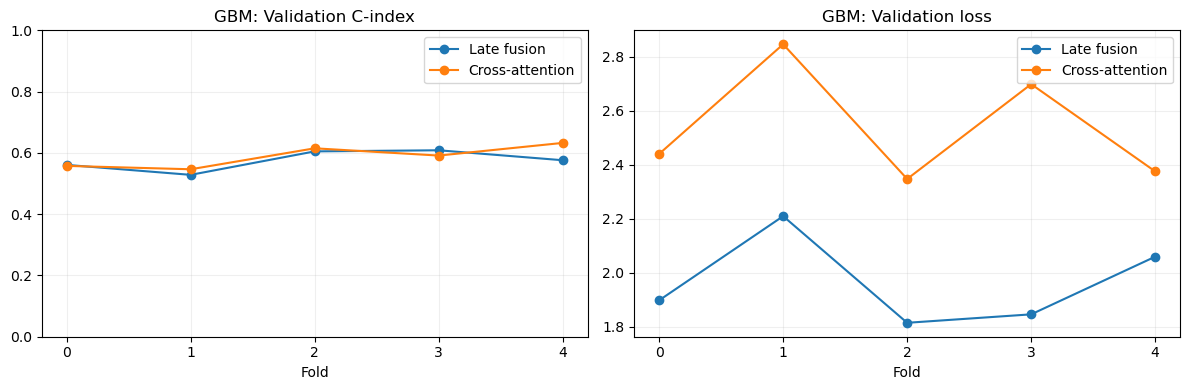

Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/multimodal/lgg_fusion_validation_by_fold.png


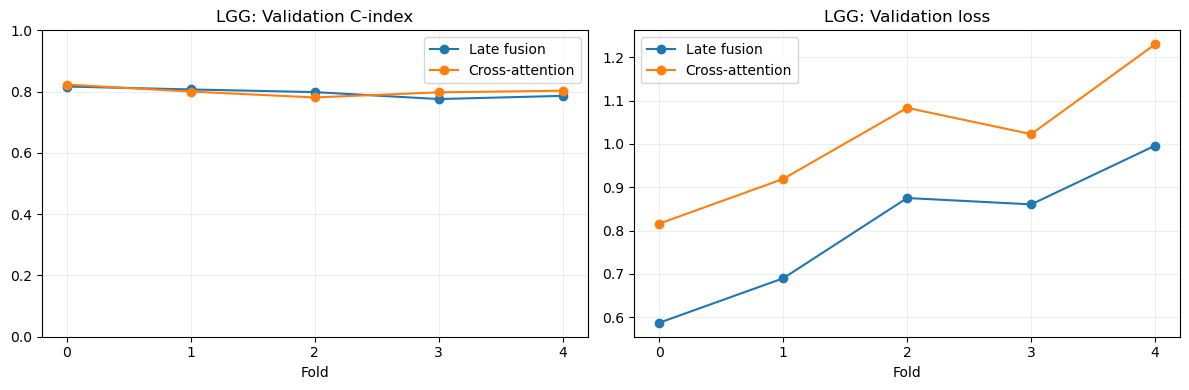

In [4]:
for cohort in COHORTS:
    available = [(name, runs[(cohort, name)]["summary"]) for name in MODELS if (cohort, name) in runs]
    if not available:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, frame in available:
        frame = frame.sort_values("fold")
        axes[0].plot(frame["fold"], frame["final_val_cindex"], marker="o", label=name)
        axes[1].plot(frame["fold"], frame["final_val_loss"], marker="o", label=name)
    for ax, title in zip(axes, ["Validation C-index", "Validation loss"]):
        ax.set(title=f"{cohort}: {title}", xlabel="Fold")
        ax.set_xticks(sorted(set().union(*(set(frame["fold"]) for _, frame in available))))
        ax.legend()
        ax.grid(alpha=0.2)
    axes[0].set_ylim(0, 1)
    fig.tight_layout()
    save_figure(fig, f"{cohort.lower()}_fusion_validation_by_fold")


## One-fold validation confusion matrices — every prediction
Use the single `FOLD` selected in setup. Every row of that fold's prediction CSV is counted, including multiple records for a patient and censored follow-up records. There is no sampling, patient averaging, or fold concatenation.

For NLL models, censored follow-up bins are not known death classes. The complete matrix is descriptive; the separate event-bin accuracy in the table uses observed deaths only. Harrell C-index uses all comparable observations from this fold.


,Cohort,Model,Fold,All validation rows,Unique patients,Censored,Observed-event bin accuracy,Harrell C-index
0,GBM,Late fusion,0,53,53,8,0.288889,0.560816
1,GBM,Cross-attention,0,53,53,8,0.311111,0.557551
2,LGG,Late fusion,0,102,102,82,0.450000,0.816561
3,LGG,Cross-attention,0,102,102,82,0.400000,0.822930


GBM Late fusion: counted 53 / 53 rows from fold 0.
GBM Cross-attention: counted 53 / 53 rows from fold 0.
Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/multimodal/gbm_fusion_fold_0_all_records_confusion_matrices.png


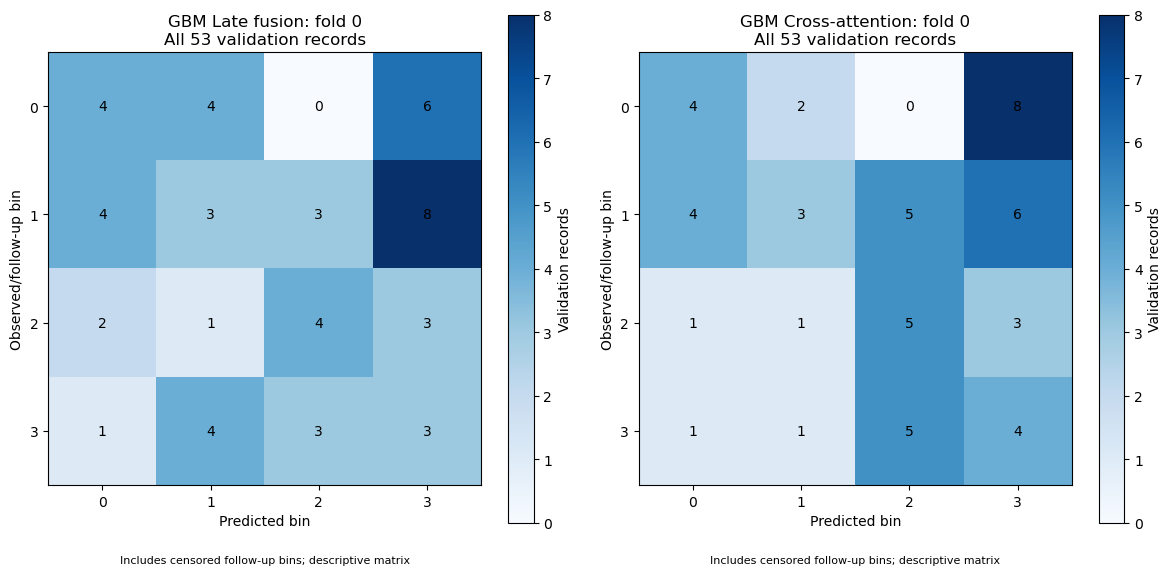

LGG Late fusion: counted 102 / 102 rows from fold 0.
LGG Cross-attention: counted 102 / 102 rows from fold 0.
Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/multimodal/lgg_fusion_fold_0_all_records_confusion_matrices.png


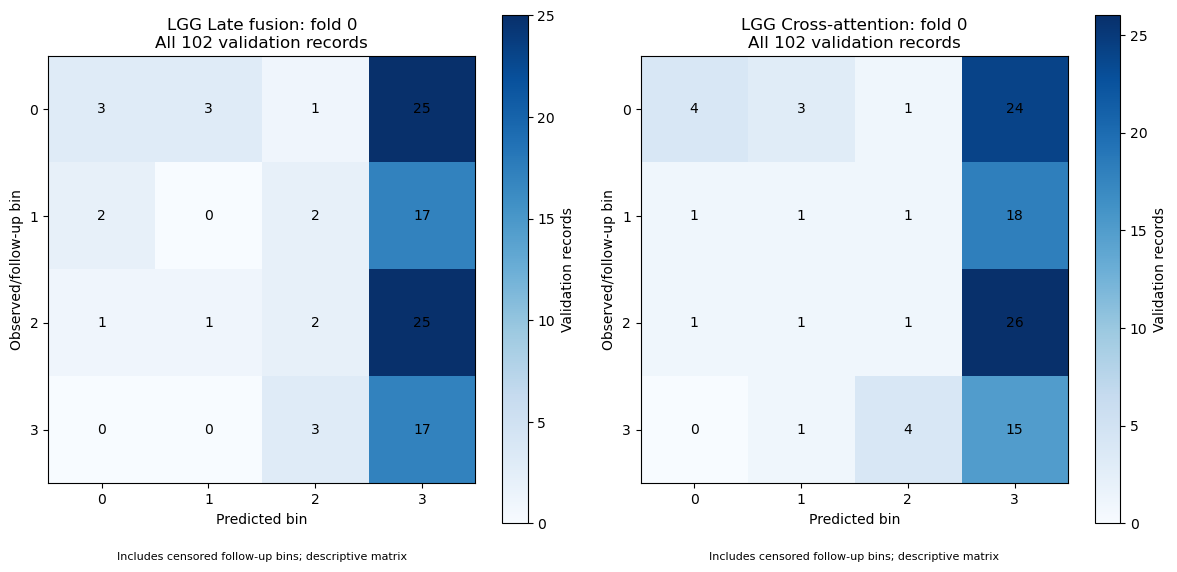

In [5]:
prediction_runs, validation_rows = {}, []
for (cohort, name), run in runs.items():
    path = ROOT / "result" / f"split_{run['model']}_{run['dataset']}_{FOLD}_predictions.csv"
    if not path.exists():
        print(f"{cohort} {name}: no prediction file for fold {FOLD}.")
        continue
    data = pd.read_csv(path)
    if data.empty:
        print(f"{cohort} {name}: empty prediction file for fold {FOLD}.")
        continue
    prediction_runs[(cohort, name)] = data
    survival = "survival_tail_probability" in data.columns
    observed = data[data["censorship"] == 0] if survival else data
    validation_rows.append({"Cohort": cohort, "Model": name, "Fold": FOLD,
        "All validation rows": len(data), "Unique patients": data["case_id"].nunique(),
        "Censored": int(data["censorship"].sum()),
        "Observed-event bin accuracy" if survival else "Class accuracy": (observed["label"] == observed["prediction"]).mean(),
        "Harrell C-index": concordance_index(data["event_time"], data["censorship"], data["risk"])})
validation_metrics = pd.DataFrame(validation_rows)
display(validation_metrics)
validation_metrics.to_csv(OUTPUT_DIR / f"gbm_lgg_fusion_fold_{FOLD}_validation.csv", index=False)

for cohort in COHORTS:
    available = [(name, prediction_runs[(cohort, name)]) for name in MODELS if (cohort, name) in prediction_runs]
    if not available:
        continue
    fig, axes = plt.subplots(1, len(available), figsize=(6 * len(available), 5.6), squeeze=False)
    for ax, (name, data) in zip(axes.flat, available):
        # Every prediction row in this fold contributes exactly once.
        matrix = pd.crosstab(data["label"], data["prediction"]).reindex(index=range(4), columns=range(4), fill_value=0)
        assert matrix.to_numpy().sum() == len(data), "Unexpected class labels."
        heat = ax.imshow(matrix, cmap="Blues", vmin=0)
        for row in range(4):
            for col in range(4):
                ax.text(col, row, matrix.loc[row, col], ha="center", va="center")
        survival = "survival_tail_probability" in data.columns
        ax.set(xticks=range(4), yticks=range(4), xlabel="Predicted bin",
               ylabel="Observed/follow-up bin" if survival else "Reference class",
               title=f"{cohort} {name}: fold {FOLD}\nAll {len(data)} validation records")
        fig.colorbar(heat, ax=ax, label="Validation records")
        if survival:
            ax.text(0.5, -0.18, "Includes censored follow-up bins; descriptive matrix", transform=ax.transAxes, ha="center", fontsize=8)
        matrix.to_csv(OUTPUT_DIR / f"{cohort.lower()}_{MODELS[name]}_fold_{FOLD}_all_records_matrix.csv")
        print(f"{cohort} {name}: counted {matrix.to_numpy().sum()} / {len(data)} rows from fold {FOLD}.")
    fig.tight_layout()
    save_figure(fig, f"{cohort.lower()}_fusion_fold_{FOLD}_all_records_confusion_matrices")


## Epoch histories and overfitting
Only histories matching the selected checkpoint's training metrics are plotted. Inner monitoring loss, when available, is shown per epoch. Outer validation remains a single final evaluation point. A large training–validation gap is consistent with overfitting; plotting changes do not improve a trained model.


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/multimodal/gbm_fusion_fold_0_learning_curves.png


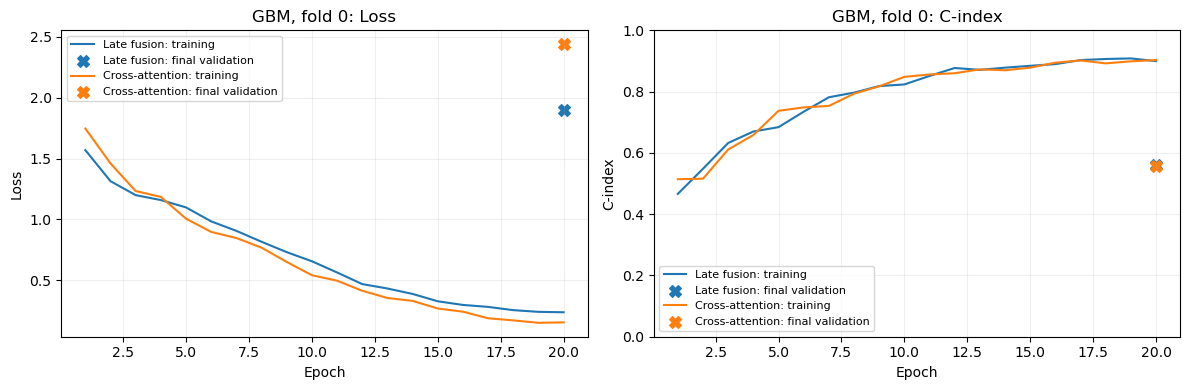

Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/multimodal/lgg_fusion_fold_0_learning_curves.png


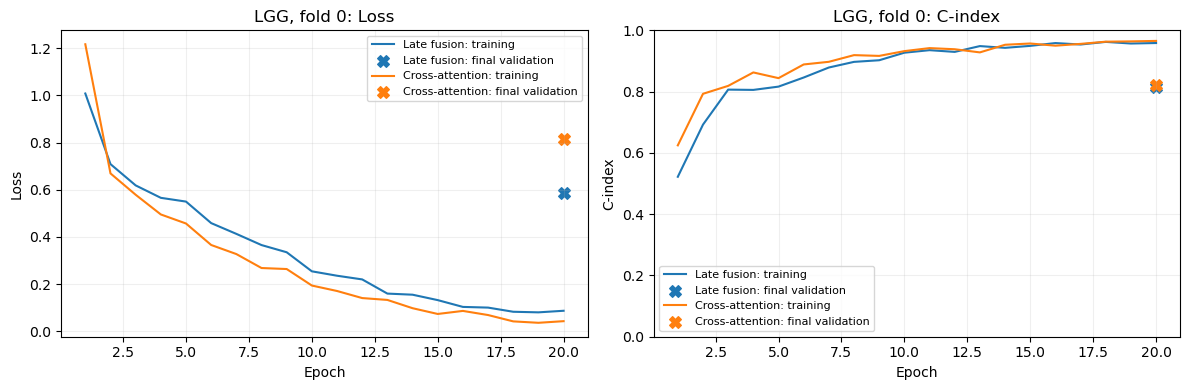

In [6]:
for cohort in COHORTS:
    histories = []
    for name in MODELS:
        run = runs.get((cohort, name))
        if run is None:
            continue
        selected = run["summary"][run["summary"]["fold"] == FOLD]
        path = run["path"].parent / f"training_history_fold_{FOLD}.csv"
        if selected.empty or not path.exists():
            print(f"{cohort} {name}: no history for fold {FOLD}.")
            continue
        history = pd.read_csv(path)
        row = selected.iloc[0]
        epoch = int(history["selected_epoch"].iloc[-1]) if not history.empty and "selected_epoch" in history else len(history)
        matches = (not history.empty and {"train_loss", "train_cindex"}.issubset(history.columns)
                   and 1 <= epoch <= len(history) and np.allclose(
                       history.iloc[epoch - 1][["train_loss", "train_cindex"]].to_numpy(float),
                       [row["train_loss"], row["train_cindex"]], rtol=1e-4, atol=1e-6))
        if not matches:
            print(f"{cohort} {name}: skipping stale or invalid history.")
            continue
        histories.append((name, history, row, epoch))
    if not histories:
        continue
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, history, row, epoch in histories:
        epochs = np.arange(1, len(history) + 1)
        for ax, train, val in [(axes[0], "train_loss", "final_val_loss"), (axes[1], "train_cindex", "final_val_cindex")]:
            line, = ax.plot(epochs, history[train], label=f"{name}: training")
            ax.scatter(epoch, row[val], marker="X", s=70, color=line.get_color(), label=f"{name}: final validation")
            if train == "train_loss" and "monitor_loss" in history:
                ax.plot(epochs, history["monitor_loss"], linestyle="--", color=line.get_color(), label=f"{name}: inner validation")
    for ax, title in zip(axes, ["Loss", "C-index"]):
        ax.set(title=f"{cohort}, fold {FOLD}: {title}", xlabel="Epoch", ylabel=title)
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
    axes[1].set_ylim(0, 1)
    fig.tight_layout()
    save_figure(fig, f"{cohort.lower()}_fusion_fold_{FOLD}_learning_curves")


## Adding the missing cohort results
Run each cohort/model combination with matching clinical, genomic, and WSI paths. For LGG, use the LGG clinical labels, expression CSV, slide metadata, and patch-feature directory together; changing only the output label would misidentify GBM data as LGG.

The expected summary locations are:
- `result/multimodal_late_fusion/normalized_zscore_gbm.csv/summary.csv`
- `result/multimodal_cross_attention/normalized_zscore_gbm.csv/summary.csv`
- `result/multimodal_late_fusion/normalized_zscore_lgg.csv/summary.csv`
- `result/multimodal_cross_attention/normalized_zscore_lgg.csv/summary.csv`

The notebook also recognizes cohort-named folders (`gbm`, `lgg`, `gbm.csv`, `lgg.csv`). Rerun all cells after generating results. Current PNG/PDF figures and CSV tables are exported to `result/comparisons/multimodal/` with cohort-specific names.


## Cross-entropy versus NLL survival comparison
The tables above now identify each run's loss. Historical summary files lack explicit loss metadata; NLL is inferred from survival prediction columns where available. Plain classification outputs cannot prove cross-entropy rather than BCE.

Add archived summaries below to compare both objectives for the same cohort and model. Existing filenames may have been overwritten, so unavailable CE results stay empty. Use C-index on identical held-out patients for comparison; absolute loss values from different objectives are not directly comparable.


In [7]:
# Optional archived runs; set the loss explicitly from the original training configuration.
ARCHIVED_LOSS_RUNS = [
    # {"Cohort": "GBM", "Model": "Late fusion", "Loss function": "Cross entropy",
    #  "path": ROOT / "result/archived_ce/summary.csv"},
]
loss_tables = [fold_results[["Cohort", "Model", "Loss function", "fold"] + metric_columns].copy()] if not fold_results.empty else []
for archived in ARCHIVED_LOSS_RUNS:
    table = pd.read_csv(archived["path"])
    table = table[pd.to_numeric(table["fold"], errors="coerce").notna()].copy()
    for key in ["Cohort", "Model", "Loss function"]:
        table[key] = archived[key]
    loss_tables.append(table[["Cohort", "Model", "Loss function", "fold"] + metric_columns])
if loss_tables:
    loss_data = pd.concat(loss_tables, ignore_index=True)
    loss_summary = loss_data.groupby(["Cohort", "Model", "Loss function"], sort=False)[metric_columns].agg(["mean", "std"])
    display(loss_summary.round(4))
    loss_summary.to_csv(OUTPUT_DIR / "fusion_loss_function_mean_std.csv")
    comparison_rows = []
    for (cohort, model), group in loss_data.groupby(["Cohort", "Model"], sort=False):
        row = {"Cohort": cohort, "Model": model}
        for objective in ["Cross entropy", "NLLSurvLoss"]:
            selected = group[group["Loss function"] == objective]
            row[f"{objective}: folds"] = selected["fold"].nunique() if len(selected) else 0
            row[f"{objective}: validation C-index"] = selected["final_val_cindex"].mean()
            row[f"{objective}: training loss"] = selected["train_loss"].mean()
            row[f"{objective}: validation loss"] = selected["final_val_loss"].mean()
        comparison_rows.append(row)
    loss_comparison = pd.DataFrame(comparison_rows)
    display(loss_comparison.round(4))
    loss_comparison.to_csv(OUTPUT_DIR / "cross_entropy_vs_nll_comparison.csv", index=False)
    if not (loss_data["Loss function"] == "Cross entropy").any():
        print("No confirmed cross-entropy run is currently saved. Add its archived summary above; CE columns remain empty.")


train_cindex         final_val_cindex  \
                                             mean     std             mean   
Cohort Model           Loss function                                         
GBM    Late fusion     NLLSurvLoss         0.8964  0.0067           0.5757   
       Cross-attention NLLSurvLoss         0.8965  0.0108           0.5886   
LGG    Late fusion     NLLSurvLoss         0.9627  0.0042           0.7968   
       Cross-attention NLLSurvLoss         0.9630  0.0074           0.8009   

                                             train_loss          \
                                         std       mean     std   
Cohort Model           Loss function                              
GBM    Late fusion     NLLSurvLoss    0.0331     0.2170  0.0184   
       Cross-attention NLLSurvLoss    0.0366     0.1507  0.0060   
LGG    Late fusion     NLLSurvLoss    0.0163     0.0669  0.0138   
       Cross-attention NLLSurvLoss    0.0150     0.0464  0.0123   

                                     final_val_loss          
                                               mean     std  
Cohort Model           Loss function                         
GBM    Late fusion     NLLSurvLoss           1.9654  0.1657  
       Cross-attention NLLSurvLoss           2.5410  0.2196  
LGG    Late fusion     NLLSurvLoss           0.8018  0.1621  
       Cross-attention NLLSurvLoss           1.0142  0.1579

,Cohort,Model,Cross entropy: folds,Cross entropy: validation C-index,Cross entropy: training loss,Cross entropy: validation loss,NLLSurvLoss: folds,NLLSurvLoss: validation C-index,NLLSurvLoss: training loss,NLLSurvLoss: validation loss
0,GBM,Late fusion,0,NaN,NaN,NaN,5,0.5757,0.2170,1.9654
1,GBM,Cross-attention,0,NaN,NaN,NaN,5,0.5886,0.1507,2.5410
2,LGG,Late fusion,0,NaN,NaN,NaN,5,0.7968,0.0669,0.8018
3,LGG,Cross-attention,0,NaN,NaN,NaN,5,0.8009,0.0464,1.0142


No confirmed cross-entropy run is currently saved. Add its archived summary above; CE columns remain empty.
